# Estudio Comparativo para la Detección de Imágenes Sintéticas (IA vs Real)
## Fase II (Parte A): Procesamiento Digital de Imágenes Tradicional mediante Descriptores LBP y SVM

### 1. Introducción y Contexto del Proyecto
El auge reciente de los modelos generativos profundos (especialmente las arquitecturas de difusión) ha transformado la visión por computador, permitiendo sintetizar imágenes con un nivel de realismo sin precedentes. La diferenciación automática entre contenido fotográfico real y material generado por inteligencia artificial constituye un desafío técnico fundamental contra la desinformación y la manipulación visual.

En el marco de la asignatura *Procesamiento de Imágenes Digitales (PID)*, este proyecto desarrolla un **estudio comparativo experimental** articulado en tres niveles progresivos de abstracción:
1. **Tier 1 (Línea Base):** Aplanamiento unidimensional de los píxeles y clasificación mediante un Perceptrón Multicapa (MLP).
2. **Tier 2 (PID Tradicional):** Extracción matemática manual de características espaciales y de frecuencia (textura y gradientes) combinadas con una Máquina de Vectores de Soporte (SVM).
3. **Tier 3 (Deep Learning Espacial):** Aprendizaje automático de filtros jerárquicos mediante una Red Neuronal Convolucional (CNN).

En este cuaderno se aborda la **primera etapa experimental del Tier 2**, aislando exclusivamente el descriptor de micro-textura **LBP (*Local Binary Patterns*)** para evaluar su capacidad discriminativa individual antes de combinarlo con el descriptor de contornos y gradientes HOG.

---

### 2. Descripción Técnica del Dataset ($128 \times 128$ RGB)
Para este experimento se emplea un conjunto de datos de mayor resolución espacial respecto al *baseline* inicial, lo que resulta especialmente relevante para el análisis de patrones locales de alta frecuencia:
- **Volumen total:** 20.000 imágenes en color (espacio RGB) con una resolución estandarizada de $128 \times 128$ píxeles.
- **División de datos (*Split* estratificado 80/20):** 16.000 imágenes destinadas al conjunto de entrenamiento (*train set*) y 4.000 imágenes reservadas para evaluación (*test set*).
- **Balanceo estricto de clases:** Proporción simétrica del 50% de imágenes reales (`real`: 8.000 train / 2.000 test) y 50% de imágenes sintéticas (`fake`: 8.000 train / 2.000 test), eliminando cualquier sesgo de clase durante el ajuste del hiperplano de decisión.

---

### 3. Consideraciones Computacionales y Restricciones de Hardware
Al igual que en la Fase I, todo el flujo de procesamiento se ejecuta en un **ordenador portátil estándar equipado con un procesador Intel Core i5 comercial y sin aceleración por GPU dedicada**. El incremento de resolución a $128 \times 128$ píxeles (16 veces más píxeles por imagen que en $32 \times 32$) exige una gestión eficiente de la memoria y del cálculo:
1. **Procesamiento bajo demanda (*Streaming* desde disco):** En lugar de cargar las 20.000 matrices de imagen simultáneamente en memoria RAM, se indexan únicamente las rutas de archivo y cada imagen se decodifica, procesa y libera individualmente tras extraer su vector compacto de características.
2. **Paralelización multi-núcleo (`joblib`):** Dado que la extracción de LBP es una operación matemáticamente independiente para cada imagen, se distribuye la carga de trabajo entre todos los hilos lógicos disponibles de la CPU (`n_jobs=-1`), reduciendo drásticamente el tiempo de cómputo.
3. **Compactación y persistencia de características:** Mediante el uso de histogramas espaciales LBP uniformes en una rejilla de $4 \times 4$ celdas, cada imagen de $128 \times 128 \times 3$ ($49.152$ valores brutos) se comprime en un vector descriptivo de tan solo **160 características numéricas** (`float32`), ocupando menos de 15 MB en memoria y permitiendo el entrenamiento rápido de la SVM en CPU.

---

### 4. Descripción y Justificación del Ecosistema de Librerías
Para la implementación técnica de esta fase se emplean las siguientes bibliotecas científicas del ecosistema Python:
- **`scikit-image` (`skimage.feature.local_binary_pattern`):** Proporciona la implementación optimizada del operador LBP, permitiendo configurar el radio de vecindad ($R$), el número de puntos de muestreo ($P$) y la variante invariante a patrones uniformes (`method='uniform'`).
- **`Pillow` (`PIL.Image`) y `NumPy`:** Gestionan la lectura eficiente desde disco, la conversión al espacio de luminancia en escala de grises (`'L'`) y la manipulación matricial necesaria para construir los histogramas normalizados por bloques espaciales.
- **`joblib` (`Parallel`, `delayed`):** Motor de paralelización utilizado para ejecutar la extracción de características sobre los múltiples núcleos del procesador Intel Core i5 sin saturar la memoria RAM.
- **`scikit-learn` (`StandardScaler`, `SVC`, `GridSearchCV`, `sklearn.metrics`):** Biblioteca estándar de aprendizaje automático empleada para estandarizar las características sin fuga de datos (*data leakage*), optimizar los hiperparámetros ($C$ y $\gamma$) de la Máquina de Vectores de Soporte con kernel RBF y extraer las métricas rigurosas de evaluación (`classification_report`, `confusion_matrix`).
- **`Matplotlib` y `Seaborn`:** Herramientas de visualización científica empleadas para representar la matriz de confusión y generar las evidencias visuales comparativas entre mapas de textura LBP e histogramas de frecuencia.

---

### 5. Objetivo Específico de este Notebook (Tier 2 - LBP)
El objetivo de este experimento es demostrar cómo la **extracción guiada de características de micro-textura** permite capturar artefactos estadísticos propios de los generadores de IA (como suavizados anómalos o inconsistencias en el ruido de alta frecuencia), evaluando cuantitativamente tanto la mejora en capacidad predictiva como el coste computacional (tiempo de extracción y latencia de inferencia por imagen).

# Fase II (Parte A): Extracción de Micro-Textura (LBP) + SVM
## 1. Configuración del Entorno, Librerías y Reproducibilidad

En este primer bloque se importan las librerías científicas necesarias para el procesamiento de imágenes, la paralelización en CPU y el aprendizaje automático. Asimismo, se establece una semilla global fija (`SEED = 42`) y se verifica el número de hilos lógicos disponibles en el procesador Intel Core i5 para optimizar el cómputo paralelo.

In [1]:
import os
import random
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Procesamiento de imágenes y descriptor LBP
from PIL import Image
from skimage.feature import local_binary_pattern

# Paralelización en CPU
import joblib
from joblib import Parallel, delayed

# Machine Learning (Preprocesamiento, Clasificador SVM y Métricas)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Control de reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

num_cores = joblib.cpu_count()
print(f"Entorno configurado correctamente.")
print(f"Núcleos lógicos detectados en CPU: {num_cores}")
print(f"Semilla global establecida en: {SEED}")

Entorno configurado correctamente.
Núcleos lógicos detectados en CPU: 8
Semilla global establecida en: 42


## 2. Indexación de Rutas y Etiquetado del Dataset

Para evitar saturar la memoria RAM cargando simultáneamente las 20.000 matrices RGB de $128 \times 128$ píxeles, en esta etapa se indexan únicamente las rutas en disco y sus etiquetas binarias correspondientes (`0` para imágenes reales `real` y `1` para imágenes sintéticas `fake`). Esto permite procesar cada muestra bajo demanda de forma ordenada y determinista.

In [2]:
TRAIN_DIR = Path("train")
TEST_DIR = Path("test")

# Mapeo explícito de etiquetas
CLASSES = {"real": 0, "fake": 1}
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def index_dataset(base_dir):
    paths = []
    labels = []
    for class_name, label in CLASSES.items():
        class_dir = base_dir / class_name
        if not class_dir.exists():
            raise FileNotFoundError(f"No se encontró el directorio: {class_dir}")
        
        # Ordenamiento alfabético para garantizar determinismo
        files = sorted([
            f for f in class_dir.iterdir()
            if f.is_file() and f.suffix.lower() in VALID_EXTENSIONS
        ])
        paths.extend(files)
        labels.extend([label] * len(files))
    return paths, np.array(labels, dtype=np.int64)

X_train_paths, y_train = index_dataset(TRAIN_DIR)
X_test_paths, y_test = index_dataset(TEST_DIR)

print(f"Mapeo de clases: {CLASSES}")
print(f"Conjunto de Entrenamiento (Train): {len(X_train_paths)} imágenes (Real: {np.sum(y_train==0)}, Fake: {np.sum(y_train==1)})")
print(f"Conjunto de Prueba (Test):         {len(X_test_paths)} imágenes (Real: {np.sum(y_test==0)}, Fake: {np.sum(y_test==1)})")

Mapeo de clases: {'real': 0, 'fake': 1}
Conjunto de Entrenamiento (Train): 16022 imágenes (Real: 8022, Fake: 8000)
Conjunto de Prueba (Test):         4005 imágenes (Real: 2005, Fake: 2000)


## 3. Extracción de Características de Micro-Textura mediante LBP

En esta etapa transformamos cada imagen bidimensional en un vector numérico compacto que caracteriza la rugosidad y el grano fino de sus superficies mediante el operador **LBP (*Local Binary Patterns*)**:

1. **Conversión a Luminancia (Escala de Grises):** Dado que LBP analiza relaciones locales de intensidad lumínica y no crominancia, cada imagen RGB ($128 \times 128 \times 3$) se convierte a escala de grises ($128 \times 128 \times 1$).
2. **Operador Circular ($P=8, R=1$):** Para cada píxel central, se compara su intensidad con $P=8$ vecinos equidistantes situados en un radio $R=1$, codificando cada comparación como un bit (`1` si el vecino es mayor o igual al centro, `0` en caso contrario).
3. **Patrones Uniformes (`method='uniform'`):** Siguiendo la formulación de Ojala et al., se agrupan los códigos binarios que presentan como máximo dos transiciones circulares (`0-1` o `1-0`), correspondientes a micro-estructuras fundamentales (puntos, bordes planos, esquinas). Todos los patrones no uniformes se acumulan en un único *bin* adicional, reduciendo la dimensionalidad de $2^8 = 256$ a **$P + 2 = 10$ valores** por histograma y aumentando la robustez frente al ruido.
4. **Preservación Espacial mediante Rejilla ($4 \times 4$):** Calcular un único histograma global sobre toda la imagen destruiría la localización espacial de las texturas. Para evitarlo, la matriz LBP de $128 \times 128$ se subdivide en **16 bloques espaciales** ($4 \times 4$ celdas de $32 \times 32$ píxeles). Se calcula el histograma normalizado (densidad de probabilidad) en cada celda y se concatenan todos los vectores, generando un descriptor final de **$16 \times 10 = 160$ características** (`float32`) por imagen.

Finalmente, los tensores resultantes se serializan en disco (`.npy`) para garantizar la persistencia de los datos y permitir su reutilización directa en la posterior fusión con el descriptor HOG sin necesidad de recomputar la extracción.

In [3]:
# Parámetros del descriptor LBP
RADIUS = 1
N_POINTS = 8 * RADIUS
METHOD = "uniform"
GRID_SIZE = 4  # Rejilla espacial 4x4 (16 bloques de 32x32 píxeles)

def extract_lbp_features(image_path):
    """
    Lee una imagen desde disco, la convierte a escala de grises y extrae
    el vector concatenado de histogramas LBP uniformes sobre una rejilla 4x4.
    """
    # 1. Lectura y conversión a escala de grises ('L')
    with Image.open(image_path) as img:
        img_gray = img.convert("L")
        img_np = np.array(img_gray, dtype=np.uint8)
    
    # 2. Cálculo de la matriz LBP 2D
    lbp_map = local_binary_pattern(img_np, N_POINTS, RADIUS, method=METHOD)
    n_bins = N_POINTS + 2  # 10 bins para P=8 con método 'uniform'
    
    # 3. Extracción de histogramas normalizados por celda espacial
    h, w = lbp_map.shape
    cell_h, cell_w = h // GRID_SIZE, w // GRID_SIZE
    features = []
    
    for i in range(GRID_SIZE):
        for j in range(GRID_SIZE):
            cell = lbp_map[i * cell_h : (i + 1) * cell_h, j * cell_w : (j + 1) * cell_w]
            hist, _ = np.histogram(cell.ravel(), bins=n_bins, range=(0, n_bins), density=True)
            features.extend(hist)
            
    return np.array(features, dtype=np.float32)

# --- EXTRACCIÓN PARALELA EN CPU ---
print("Iniciando extracción paralela de características LBP (20.027 imágenes)...")

t0_train = time.time()
X_train_lbp = np.array(
    Parallel(n_jobs=-1, verbose=1)(delayed(extract_lbp_features)(p) for p in X_train_paths)
)
time_extract_train = time.time() - t0_train

t0_test = time.time()
X_test_lbp = np.array(
    Parallel(n_jobs=-1, verbose=1)(delayed(extract_lbp_features)(p) for p in X_test_paths)
)
time_extract_test = time.time() - t0_test

total_extract_time = time_extract_train + time_extract_test
avg_extract_ms = (time_extract_test / len(X_test_paths)) * 1000

print(f"\n--- RESUMEN DE EXTRACCIÓN LBP ---")
print(f"Tiempo extracción Train ({len(X_train_paths)} imgs): {time_extract_train:.2f} s")
print(f"Tiempo extracción Test  ({len(X_test_paths)} imgs):  {time_extract_test:.2f} s")
print(f"Tiempo total de extracción:          {total_extract_time:.2f} s")
print(f"Coste medio de extracción por imagen: {avg_extract_ms:.4f} ms")
print(f"Dimensión tensor Train: {X_train_lbp.shape} | Memoria: {X_train_lbp.nbytes / (1024**2):.2f} MB")
print(f"Dimensión tensor Test:  {X_test_lbp.shape} | Memoria: {X_test_lbp.nbytes / (1024**2):.2f} MB")

# Persistencia en disco para reutilización en fases posteriores (HOG + LBP)
np.save("X_train_lbp_20k.npy", X_train_lbp)
np.save("X_test_lbp_20k.npy", X_test_lbp)
np.save("y_train_20k.npy", y_train)
np.save("y_test_20k.npy", y_test)
print("\nTensores LBP guardados correctamente en disco (.npy).")

Iniciando extracción paralela de características LBP (20.027 imágenes)...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    2.6s
[Parallel(n_jobs=-1)]: Done 920 tasks      | elapsed:    5.9s
[Parallel(n_jobs=-1)]: Done 2920 tasks      | elapsed:   13.9s
[Parallel(n_jobs=-1)]: Done 5720 tasks      | elapsed:   24.0s
[Parallel(n_jobs=-1)]: Done 9320 tasks      | elapsed:   35.9s
[Parallel(n_jobs=-1)]: Done 13720 tasks      | elapsed:   52.9s
[Parallel(n_jobs=-1)]: Done 16022 out of 16022 | elapsed:  1.0min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  56 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 1200 tasks      | elapsed:    4.3s
[Parallel(n_jobs=-1)]: Done 3200 tasks      | elapsed:   11.9s



--- RESUMEN DE EXTRACCIÓN LBP ---
Tiempo extracción Train (16022 imgs): 61.48 s
Tiempo extracción Test  (4005 imgs):  15.13 s
Tiempo total de extracción:          76.61 s
Coste medio de extracción por imagen: 3.7769 ms
Dimensión tensor Train: (16022, 160) | Memoria: 9.78 MB
Dimensión tensor Test:  (4005, 160) | Memoria: 2.44 MB

Tensores LBP guardados correctamente en disco (.npy).


[Parallel(n_jobs=-1)]: Done 4005 out of 4005 | elapsed:   15.0s finished


## 4. Estandarización de Características y Entrenamiento del Clasificador (SVM)

Una vez extraídos los vectores descriptores LBP de 160 dimensiones, se procede al ajuste del modelo de clasificación supervisada mediante una **Máquina de Vectores de Soporte (SVM)**:

1. **Estandarización Estadística (`StandardScaler`):** Los algoritmos basados en distancias métricas en espacios multidimensionales son sensibles a las diferencias de escala entre características. Se aplica una normalización Z-score ($\mu = 0, \sigma = 1$) ajustada **exclusivamente sobre el conjunto de entrenamiento (`fit_transform`)** y aplicada posteriormente al conjunto de prueba (`transform`), evitando cualquier fuga de información (*data leakage*).
2. **Clasificación No Lineal mediante Kernel RBF:** Dado que las distribuciones de micro-texturas reales y sintéticas no son linealmente separables en el espacio original, se emplea un kernel de Base Radial (*Radial Basis Function*, RBF), que proyecta los vectores a un espacio de mayor dimensionalidad para trazar una frontera de decisión óptima maximizando el margen entre clases.
3. **Optimización de Hiperparámetros (`GridSearchCV`):** Se realiza una búsqueda en rejilla con validación cruzada estratificada de 3 particiones (`cv=3`) sobre los parámetros críticos del modelo:
   - **$C$ (Penalización de error):** Controla el compromiso entre maximizar el margen de separación y minimizar los errores de clasificación en entrenamiento.
   - **$\gamma$ (Coeficiente del kernel RBF):** Define el radio de influencia de cada vector de soporte sobre la curvatura de la frontera de decisión.

In [4]:
# 1. Estandarización sin Data Leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_lbp)
X_test_scaled = scaler.transform(X_test_lbp)

# 2. Definición de la rejilla de hiperparámetros para SVM (Kernel RBF)
param_grid = {
    "C": [1, 10, 50],
    "gamma": ["scale", 0.01, 0.001],
    "kernel": ["rbf"]
}

# cache_size=1000 reserva 1GB de RAM para acelerar el cálculo matricial del kernel en CPU
svm_base = SVC(cache_size=1000, random_state=SEED)

grid_search = GridSearchCV(
    estimator=svm_base,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

print("Iniciando búsqueda de hiperparámetros y entrenamiento de la SVM (16.022 muestras)...")
t0_train = time.time()
grid_search.fit(X_train_scaled, y_train)
train_time = time.time() - t0_train

best_svm = grid_search.best_estimator_

print(f"\n--- RESUMEN DE ENTRENAMIENTO SVM ---")
print(f"Tiempo total de entrenamiento y validación cruzada: {train_time:.2f} segundos")
print(f"Mejores hiperparámetros seleccionados: {grid_search.best_params_}")
print(f"Precisión media en Validación Cruzada (Train CV): {grid_search.best_score_ * 100:.2f}%")
print(f"Número total de Vectores de Soporte aprendidos: {best_svm.n_support_.sum()} (Real: {best_svm.n_support_[0]}, Fake: {best_svm.n_support_[1]})")

Iniciando búsqueda de hiperparámetros y entrenamiento de la SVM (16.022 muestras)...
Fitting 3 folds for each of 9 candidates, totalling 27 fits

--- RESUMEN DE ENTRENAMIENTO SVM ---
Tiempo total de entrenamiento y validación cruzada: 428.72 segundos
Mejores hiperparámetros seleccionados: {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
Precisión media en Validación Cruzada (Train CV): 73.67%
Número total de Vectores de Soporte aprendidos: 12226 (Real: 6268, Fake: 5958)


## 5. Evaluación en Conjunto de Prueba (Test Set) y Exportación del Modelo

En esta sección se evalúa la capacidad de generalización del clasificador SVM entrenado sobre las **4.005 imágenes inéditas del conjunto de prueba (*test set*)**. Se calculan:
- **Métricas de Clasificación:** *Accuracy*, *Precision*, *Recall* y *F1-Score* desglosados por clase (`real` vs `fake`), junto con la **Matriz de Confusión** para inspeccionar la simetría de los errores (falsos positivos y falsos negativos).
- **Coste Computacional en Inferencia:** Se mide la latencia media por imagen sumando tanto el tiempo de extracción del descriptor LBP como el tiempo de evaluación del hiperplano de la SVM.
- **Serialización del Pipeline:** Se exportan tanto el estandarizador (`StandardScaler`) como el modelo entrenado (`SVC`) mediante `joblib` para garantizar su reproducibilidad.

--- MÉTRICAS DE RENDIMIENTO EN TEST SET (LBP + SVM) ---
Accuracy:  75.28%
Precision: 74.40%
Recall:    77.00%
F1-Score:  75.68%

--- COSTE COMPUTACIONAL EN INFERENCIA ---
Latencia extracción LBP:   3.7769 ms / imagen
Latencia predicción SVM:   4.7455 ms / imagen
Latencia total end-to-end: 8.5224 ms / imagen

--- INFORME DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

    REAL (0)     0.7623    0.7357    0.7487      2005
    FAKE (1)     0.7440    0.7700    0.7568      2000

    accuracy                         0.7528      4005
   macro avg     0.7531    0.7528    0.7527      4005
weighted avg     0.7531    0.7528    0.7527      4005



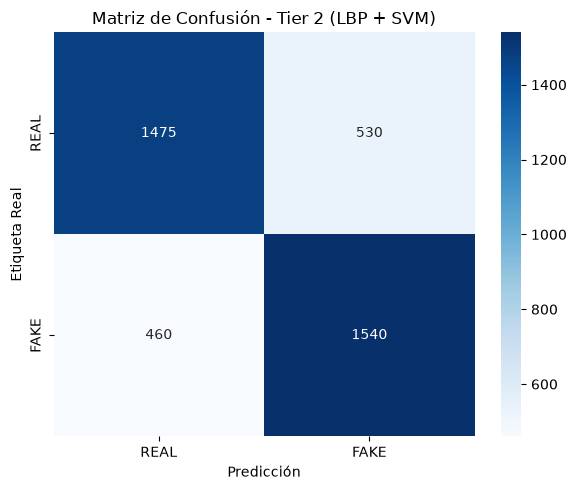

Modelo y escalador guardados correctamente en 'tier2_lbp_svm_20k.joblib'


In [5]:
# 1. Predicción sobre el conjunto de prueba y medición de latencia
t0_infer = time.time()
y_pred = best_svm.predict(X_test_scaled)
svm_infer_total_time = time.time() - t0_infer

# Cálculo de latencia media por imagen (Extracción LBP + Clasificación SVM)
lbp_latency_ms = (time_extract_test / len(X_test_paths)) * 1000
svm_latency_ms = (svm_infer_total_time / len(X_test_paths)) * 1000
total_latency_ms = lbp_latency_ms + svm_latency_ms

print("--- MÉTRICAS DE RENDIMIENTO EN TEST SET (LBP + SVM) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred) * 100:.2f}%")
print(f"Recall:    {recall_score(y_test, y_pred) * 100:.2f}%")
print(f"F1-Score:  {f1_score(y_test, y_pred) * 100:.2f}%")

print(f"\n--- COSTE COMPUTACIONAL EN INFERENCIA ---")
print(f"Latencia extracción LBP:   {lbp_latency_ms:.4f} ms / imagen")
print(f"Latencia predicción SVM:   {svm_latency_ms:.4f} ms / imagen")
print(f"Latencia total end-to-end: {total_latency_ms:.4f} ms / imagen")

# 2. Informe detallado de clasificación
class_names = ["REAL (0)", "FAKE (1)"]
print("\n--- INFORME DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

# 3. Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["REAL", "FAKE"],
    yticklabels=["REAL", "FAKE"]
)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta Real")
plt.title("Matriz de Confusión - Tier 2 (LBP + SVM)")
plt.tight_layout()
plt.savefig("confusion_matrix_lbp_20k.png", dpi=150)
plt.show()

# 4. Guardar el modelo y el escalador en disco
joblib.dump({"scaler": scaler, "svm": best_svm}, "tier2_lbp_svm_20k.joblib")
print("Modelo y escalador guardados correctamente en 'tier2_lbp_svm_20k.joblib'")

## 6. Análisis Cualitativo y Evidencias Visuales (Mapas LBP)

Con el objetivo de enriquecer la discusión experimental de la Fase IV, se visualiza el comportamiento interno del descriptor LBP comparando una muestra fotográfica real (`real`) frente a una imagen generada por IA (`fake`). Para cada caso se representa:
1. **Imagen Original ($128 \times 128$ RGB).**
2. **Mapa Espacial de Códigos LBP:** Representación bidimensional de los patrones locales detectados en cada vecindad $3 \times 3$.
3. **Histograma Global Normalizado (Patrones Uniformes):** Distribución estadística de los 10 *bins* que alimentan al clasificador SVM.

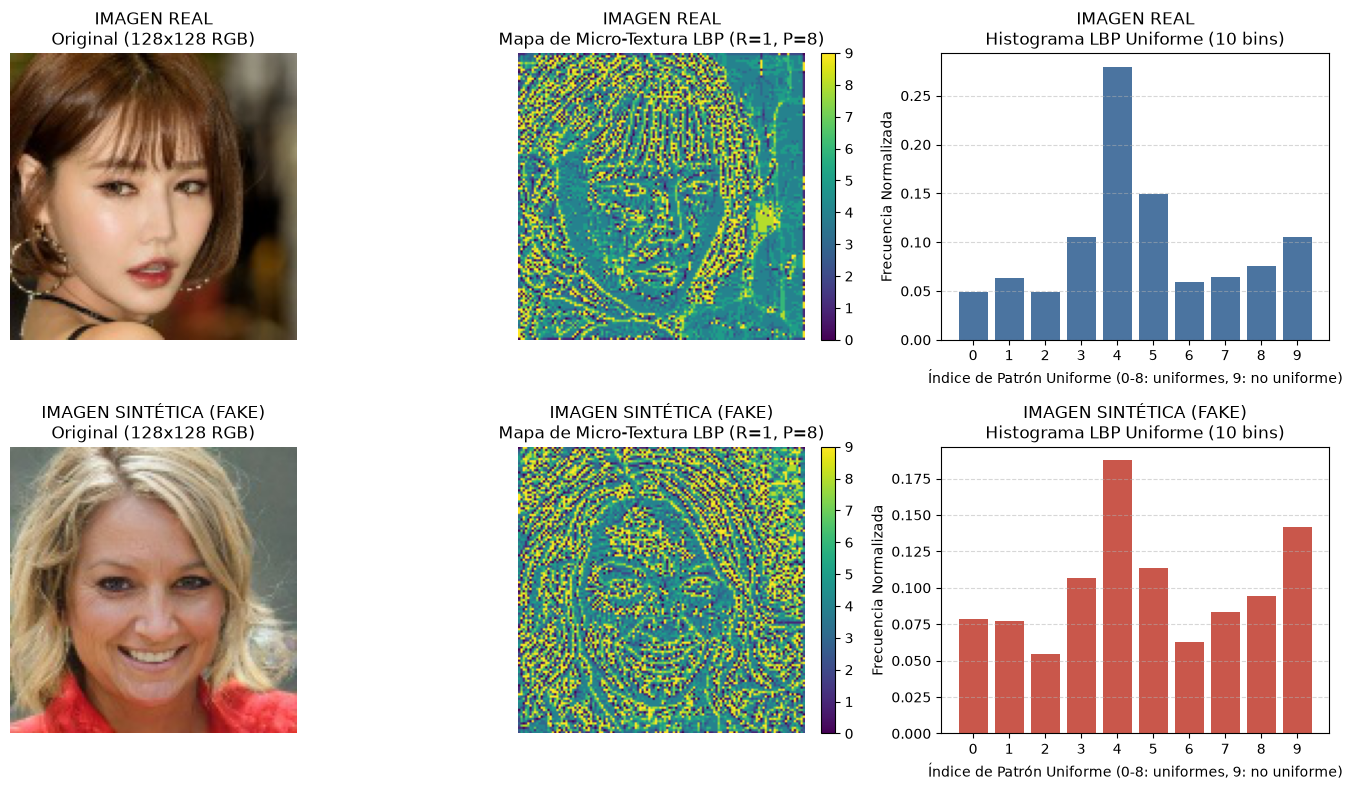

In [6]:
def visualize_lbp_comparison(real_path, fake_path):
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    samples = [("IMAGEN REAL", real_path), ("IMAGEN SINTÉTICA (FAKE)", fake_path)]
    n_bins = N_POINTS + 2

    for row, (title, img_path) in enumerate(samples):
        img_rgb = Image.open(img_path).convert("RGB")
        img_gray = np.array(img_rgb.convert("L"), dtype=np.uint8)
        lbp_map = local_binary_pattern(img_gray, N_POINTS, RADIUS, method=METHOD)
        hist, _ = np.histogram(lbp_map.ravel(), bins=n_bins, range=(0, n_bins), density=True)

        # Columna 1: Imagen Original
        axes[row, 0].imshow(img_rgb)
        axes[row, 0].set_title(f"{title}\nOriginal (128x128 RGB)")
        axes[row, 0].axis("off")

        # Columna 2: Mapa 2D LBP
        im = axes[row, 1].imshow(lbp_map, cmap="viridis")
        axes[row, 1].set_title(f"{title}\nMapa de Micro-Textura LBP (R={RADIUS}, P={N_POINTS})")
        axes[row, 1].axis("off")
        plt.colorbar(im, ax=axes[row, 1], fraction=0.046, pad=0.04)

        # Columna 3: Histograma de Patrones Uniformes
        axes[row, 2].bar(range(n_bins), hist, color="#2b5c8f" if row == 0 else "#c0392b", alpha=0.85)
        axes[row, 2].set_title(f"{title}\nHistograma LBP Uniforme (10 bins)")
        axes[row, 2].set_xlabel("Índice de Patrón Uniforme (0-8: uniformes, 9: no uniforme)")
        axes[row, 2].set_ylabel("Frecuencia Normalizada")
        axes[row, 2].set_xticks(range(n_bins))
        axes[row, 2].grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.savefig("evidencia_visual_lbp_20k.png", dpi=150)
    plt.show()

# Seleccionamos la primera imagen Real y la primera imagen Fake del conjunto de prueba
sample_real_path = X_test_paths[0]
sample_fake_path = X_test_paths[np.where(y_test == 1)[0][0]]

visualize_lbp_comparison(sample_real_path, sample_fake_path)